In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
from datasets import load_dataset

df = load_dataset("bentrevett/multi30k")
print(df.shape)

{'train': (29000, 2), 'validation': (1014, 2), 'test': (1000, 2)}


In [3]:
train = df["train"]
print(len(train))

29000


In [4]:
validate = df["validation"]
print(len(validate))

1014


In [5]:
test = df["test"]
print(len(test))

1000


In [6]:
print("German:", train[0]["de"])
print("English:", train[0]["en"])

German: Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.
English: Two young, White males are outside near many bushes.


In [7]:
train_df = pd.DataFrame({
    "German": train["de"],
    "English": train["en"]
})

val_df = pd.DataFrame({
    "German": validate["de"],
    "English": validate["en"]
})

test_df = pd.DataFrame({
    "German": test["de"],
    "English": test["en"]
})

print(train_df.sample(5, random_state=42))

                                                  German  \
2884   Ein kleiner Junge mit Sweatshirt und Stiefeln,...   
12220  Mehrere Personen in blauer und grüner Kleidung...   
20437  Ein Mann in weißer kurzer Hose wirft in einem ...   
25172  Ein rot gekleidete Mann steht hinter den Kette...   
20676  Eine ältere Frau geht durch den Regen und hält...   

                                                 English  
2884   Little boy pulling a green wagon wearing a swe...  
12220  Several people stand outside, singing in blue ...  
20437  A man in white shorts is in a park throwing a ...  
25172  The man in red stands behind the chains while ...  
20676  An older woman walks in the rain holding a red...  


In [8]:
train_df.nunique()

German     28975
English    28991
dtype: int64

In [9]:
train_df.isnull().sum()

German     0
English    0
dtype: int64

In [10]:
train_df.duplicated().sum()

np.int64(3)

In [ ]:
train_df = train_df.drop_duplicates(subset=["German", "English"]).reset_index(drop=True)
print(train_df.duplicated())

In [11]:
print(train_df["German"].head())
print(train_df["English"].head())

0    Zwei junge weiße Männer sind im Freien in der ...
1    Mehrere Männer mit Schutzhelmen bedienen ein A...
2    Ein kleines Mädchen klettert in ein Spielhaus ...
3    Ein Mann in einem blauen Hemd steht auf einer ...
4    Zwei Männer stehen am Herd und bereiten Essen zu.
Name: German, dtype: str
0    Two young, White males are outside near many b...
1    Several men in hard hats are operating a giant...
2      A little girl climbing into a wooden playhouse.
3    A man in a blue shirt is standing on a ladder ...
4             Two men are at the stove preparing food.
Name: English, dtype: str


In [12]:
train_df.columns

Index(['German', 'English'], dtype='str')

In [13]:
train_df["German_Length"] = train_df["German"].apply(
    lambda x: len(x.split())
)

train_df["English_Length"] = train_df["English"].apply(
    lambda x: len(x.split())
)

In [14]:
train_df.describe()

,German_Length,English_Length
count,29000.000000,29000.000000
mean,11.116655,11.897241
std,3.837722,3.800192
min,1.000000,3.000000
25%,8.000000,9.000000
50%,11.000000,11.000000
75%,13.000000,14.000000
max,39.000000,37.000000


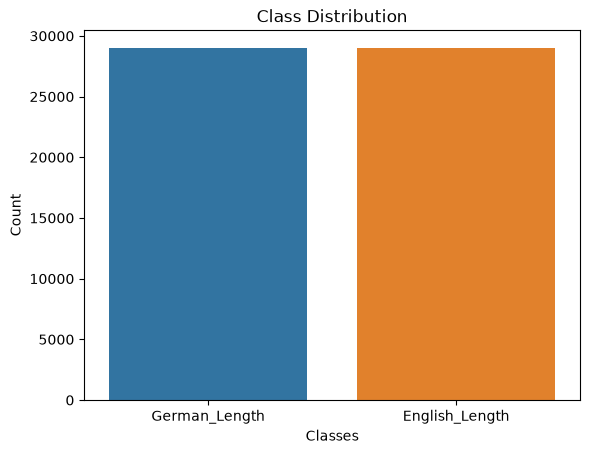

In [39]:
sns.countplot(data=train_df)
plt.title("Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Count")
plt.show()

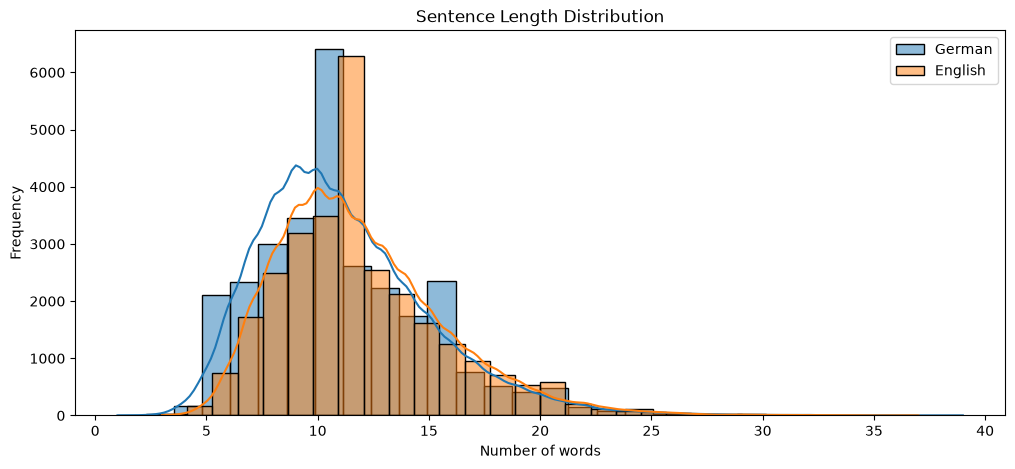

In [16]:
plt.figure(figsize=(12, 5))

sns.histplot(
    train_df["German_Length"],
    bins=30,
    kde=True,
    label="German",
    alpha=0.5
)

sns.histplot(
    train_df["English_Length"],
    bins=30,
    kde=True,
    label="English",
    alpha=0.5
)

plt.title("Sentence Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [17]:
from collections import Counter

german_words = Counter(
    word.lower()
    for sentence in train_df["German"]
    for word in sentence.split()
)

english_words = Counter(
    word.lower()
    for sentence in train_df["English"]
    for word in sentence.split()
)

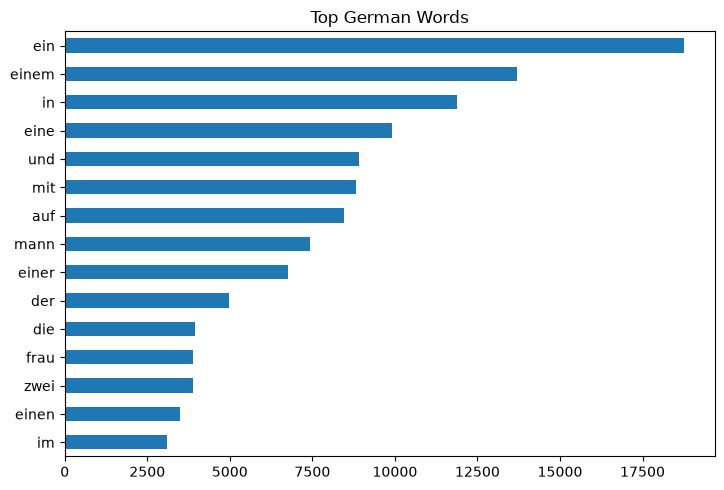

In [18]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

pd.Series(
    dict(german_words.most_common(15))
).sort_values().plot(kind="barh")

plt.title("Top German Words")
plt.tight_layout()
plt.show()

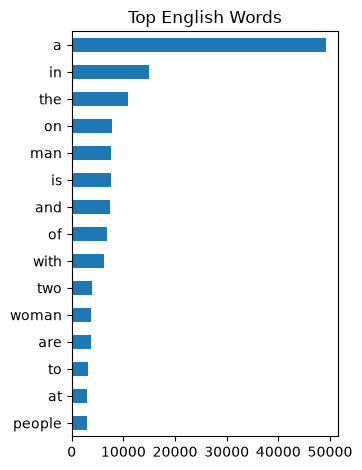

In [19]:
plt.subplot(1, 2, 2)

pd.Series(
    dict(english_words.most_common(15))
).sort_values().plot(kind="barh")

plt.title("Top English Words")
plt.tight_layout()
plt.show()

In [21]:
import re

def clean_text(text):

    text = text.lower().strip()

    text = re.sub(r"\s+", " ", text)

    text = re.sub(
        r"([?.!,;:])",
        r" \1 ",
        text
    )

    text = re.sub(r"\s+", " ", text)

    return text.strip()


train_df["German"] = train_df["German"].apply(clean_text)
train_df["English"] = train_df["English"].apply(clean_text)

val_df["German"] = val_df["German"].apply(clean_text)
val_df["English"] = val_df["English"].apply(clean_text)

test_df["German"] = test_df["German"].apply(clean_text)
test_df["English"] = test_df["English"].apply(clean_text)

In [22]:
train_df["English"] = (
    "startseq " + train_df["English"] + " endseq"
)

val_df["English"] = (
    "startseq " + val_df["English"] + " endseq"
)

test_df["English"] = (
    "startseq " + test_df["English"] + " endseq"
)

print("German:", train_df.iloc[0]["German"])
print("English:", train_df.iloc[0]["English"])

German: zwei junge weiße männer sind im freien in der nähe vieler büsche .
English: startseq two young , white males are outside near many bushes . endseq


In [23]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

german_vectorizer = TextVectorization(
    max_tokens=12000,
    output_mode="int",
    output_sequence_length=40,
    standardize=None
)

english_vectorizer = TextVectorization(
    max_tokens=12000,
    output_mode="int",
    output_sequence_length=40,
    standardize=None
)

In [24]:
german_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        train_df["German"].values
    ).batch(256)
)

english_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(
        train_df["English"].values
    ).batch(256)
)

GERMAN_VOCAB_SIZE = german_vectorizer.vocabulary_size()
ENGLISH_VOCAB_SIZE = english_vectorizer.vocabulary_size()

print("German vocabulary:", GERMAN_VOCAB_SIZE)
print("English vocabulary:", ENGLISH_VOCAB_SIZE)

German vocabulary: 12000
English vocabulary: 10527


In [25]:
print("German vocabulary:")
print(german_vectorizer.get_vocabulary()[:30])

print("\nEnglish vocabulary:")
print(english_vectorizer.get_vocabulary()[:30])

German vocabulary:
['', '[UNK]', np.str_('.'), np.str_('ein'), np.str_('einem'), np.str_('in'), np.str_('eine'), np.str_(','), np.str_('und'), np.str_('mit'), np.str_('auf'), np.str_('mann'), np.str_('einer'), np.str_('der'), np.str_('frau'), np.str_('die'), np.str_('zwei'), np.str_('einen'), np.str_('im'), np.str_('an'), np.str_('von'), np.str_('sich'), np.str_('dem'), np.str_('mädchen'), np.str_('junge'), np.str_('vor'), np.str_('zu'), np.str_('steht'), np.str_('männer'), np.str_('sitzt')]

English vocabulary:
['', '[UNK]', np.str_('a'), np.str_('startseq'), np.str_('endseq'), np.str_('.'), np.str_('in'), np.str_('the'), np.str_('on'), np.str_('man'), np.str_('is'), np.str_('and'), np.str_('of'), np.str_('with'), np.str_(','), np.str_('woman'), np.str_('two'), np.str_('are'), np.str_('to'), np.str_('people'), np.str_('at'), np.str_('an'), np.str_('wearing'), np.str_('young'), np.str_('white'), np.str_('shirt'), np.str_('black'), np.str_('his'), np.str_('while'), np.str_('blue')]


In [26]:
german_sequences = german_vectorizer(train_df["German"].values)
english_sequences = english_vectorizer(train_df["English"].values)

print("German sequence:")
print(german_sequences[0].numpy())

print("\nEnglish sequence:")
print(english_sequences[0].numpy())

German sequence:
[  16   24  249   28   82   18   86    5   13  108 5555 3469    2    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]

English sequence:
[   3   16   23   14   24  775   17   56   79  194 1334    5    4    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0]


In [27]:
english_vocab = english_vectorizer.get_vocabulary()

START_ID = english_vocab.index("startseq")
END_ID = english_vocab.index("endseq")

print("Padding ID:", 0)
print("Unknown ID:", 1)
print("Start ID:", START_ID)
print("End ID:", END_ID)

Padding ID: 0
Unknown ID: 1
Start ID: 3
End ID: 4


In [28]:
X_train_de = german_vectorizer(train_df["German"].values)
Y_train = english_vectorizer(train_df["English"].values)

X_val_de = german_vectorizer(val_df["German"].values)
Y_val = english_vectorizer(val_df["English"].values)

X_test_de = german_vectorizer(test_df["German"].values)
Y_test = english_vectorizer(test_df["English"].values)

In [29]:
decoder_train = Y_train[:, :-1]
target_train = Y_train[:, 1:]

decoder_val = Y_val[:, :-1]
target_val = Y_val[:, 1:]

decoder_test = Y_test[:, :-1]
target_test = Y_test[:, 1:]

print("Encoder input:", X_train_de.shape)
print("Decoder input:", decoder_train.shape)
print("Expected output:", target_train.shape)

Encoder input: (28997, 40)
Decoder input: (28997, 39)
Expected output: (28997, 39)


In [30]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        (X_train_de, decoder_train),
        target_train
    )
)

train_dataset = (
    train_dataset
    .shuffle(10000, seed=42)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = tf.data.Dataset.from_tensor_slices(
    (
        (X_val_de, decoder_val),
        target_val
    )
)

val_dataset = (
    val_dataset
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        (X_test_de, decoder_test),
        target_test
    )
)

test_dataset = (
    test_dataset
    .batch(42)
    .prefetch(tf.data.AUTOTUNE)
)

In [31]:
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True,
    reduction="none"
)

In [32]:
def masked_loss(y_true, y_pred):

    loss = loss_function(y_true, y_pred)

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        loss.dtype
    )

    return tf.reduce_sum(loss * mask) / tf.maximum(
        tf.reduce_sum(mask), 1.0
    )

In [33]:
def masked_accuracy(y_true, y_pred):

    predictions = tf.argmax(
        y_pred,
        axis=-1,
        output_type=y_true.dtype
    )

    correct = tf.cast(
        tf.equal(y_true, predictions),
        tf.float32
    )

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        tf.float32
    )

    return tf.reduce_sum(correct * mask) / tf.maximum(
        tf.reduce_sum(mask), 1.0
    )

In [41]:
from tensorflow.keras import Input, Model
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout, AdditiveAttention, Concatenate, LayerNormalization

def build_seq2seq_model(rnn_type, use_attention=False, model_name="Seq2Seq"):
    
    source_input = Input(
        shape=(40,),
        name="german_input"
    )

    target_input = Input(
        shape=(39,),
        name="english_input"
    )

    
    source_mask = source_input != 0
    target_mask = target_input != 0

    
    source_embedding = Embedding(
        GERMAN_VOCAB_SIZE,
        128,
        mask_zero=True,
        name=f"{model_name}_source_embedding"
    )(source_input)

    target_embedding = Embedding(
        ENGLISH_VOCAB_SIZE,
        128,
        mask_zero=True,
        name=f"{model_name}_target_embedding"
    )(target_input)

    
    encoder_outputs = source_embedding
    encoder_states = []

    for i in range(2):

        encoder = rnn_type(
            256,
            return_sequences=True,
            return_state=True,
            dropout=0.2,
            name=f"{model_name}_encoder_{i+1}"
        )

        result = encoder(encoder_outputs)

        encoder_outputs = result[0]
        encoder_states.append(result[1:])

    
    decoder_outputs = target_embedding

    for i in range(2):

        decoder = rnn_type(
            256,
            return_sequences=True,
            return_state=True,
            dropout=0.2,
            name=f"{model_name}_decoder_{i+1}"
        )

        result = decoder(
            decoder_outputs,
            initial_state=encoder_states[i]
        )

        decoder_outputs = result[0]

    
    if use_attention:

        attention = AdditiveAttention(
            name=f"{model_name}_attention"
        )

        context = attention(
            [decoder_outputs, encoder_outputs],
            mask=[target_mask, source_mask]
        )

        decoder_outputs = Concatenate(
            axis=-1
        )([
            decoder_outputs,
            context
        ])

        decoder_outputs = LayerNormalization()(
            decoder_outputs
        )

    
    output = Dense(
        ENGLISH_VOCAB_SIZE,
        name=f"{model_name}_output"
    )(decoder_outputs)

    model = Model(
        inputs=[source_input, target_input],
        outputs=output,
        name=model_name
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001,
            clipnorm=1.0
        ),
        loss=masked_loss,
        metrics=[masked_accuracy]
    )

    return model


In [42]:
lstm_baseline = build_seq2seq_model(
    rnn_type=LSTM,
    use_attention=False,
    model_name="LSTM_Seq2Seq"
)

gru_baseline = build_seq2seq_model(
    rnn_type=GRU,
    use_attention=False,
    model_name="GRU_Seq2Seq"
)

lstm_attention = build_seq2seq_model(
    rnn_type=LSTM,
    use_attention=True,
    model_name="LSTM_Attention"
)

gru_attention = build_seq2seq_model(
    rnn_type=GRU,
    use_attention=True,
    model_name="GRU_Attention"
)


models = {
    "LSTM": lstm_baseline,
    "GRU": gru_baseline,
    "LSTM_Attention": lstm_attention,
    "GRU_Attention": gru_attention
}


for name, model in models.items():

    print("\n", "=" * 60)
    print(name)
    print("=" * 60)

    model.summary()




LSTM


Model: "LSTM_Seq2Seq"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ german_input        │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ english_input       │ (None, 39)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_sourc… │ (None, 40, 128)   │  1,536,000 │ german_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 40)        │          0 │ german_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_targe… │ (None, 39, 128)   │  1,347,456 │ english_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_encod… │ [(None, 40, 256), │    394,240 │ LSTM_Seq2Seq_sou… │
│ (LSTM)              │ (None, 256),      │            │ not_equal_4[0][0] │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_decod… │ [(None, 39, 256), │    394,240 │ LSTM_Seq2Seq_tar… │
│ (LSTM)              │ (None, 256),      │            │ LSTM_Seq2Seq_enc… │
│                     │ (None, 256)]      │            │ LSTM_Seq2Seq_enc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_encod… │ [(None, 40, 256), │    525,312 │ LSTM_Seq2Seq_enc… │
│ (LSTM)              │ (None, 256),      │            │ not_equal_4[0][0] │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_decod… │ [(None, 39, 256), │    525,312 │ LSTM_Seq2Seq_dec… │
│ (LSTM)              │ (None, 256),      │            │ LSTM_Seq2Seq_enc… │
│                     │ (None, 256)]      │            │ LSTM_Seq2Seq_enc… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ LSTM_Seq2Seq_output │ (None, 39, 10527) │  2,705,439 │ LSTM_Seq2Seq_dec… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,427,999 (28.34 MB)

 Trainable params: 7,427,999 (28.34 MB)

 Non-trainable params: 0 (0.00 B)

... (14 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ german_input        │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ english_input       │ (None, 39)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_sour… │ (None, 40, 128)   │  1,536,000 │ german_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_16        │ (None, 40)        │          0 │ german_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_targ… │ (None, 39, 128)   │  1,347,456 │ english_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_enco… │ [(None, 40, 256), │    296,448 │ GRU_Attention_so… │
│ (GRU)               │ (None, 256)]      │            │ not_equal_16[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_deco… │ [(None, 39, 256), │    296,448 │ GRU_Attention_ta… │
│ (GRU)               │ (None, 256)]      │            │ GRU_Attention_en… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_enco… │ [(None, 40, 256), │    394,752 │ GRU_Attention_en… │
│ (GRU)               │ (None, 256)]      │            │ not_equal_16[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_deco… │ [(None, 39, 256), │    394,752 │ GRU_Attention_de… │
│ (GRU)               │ (None, 256)]      │            │ GRU_Attention_en… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_15        │ (None, 39)        │          0 │ english_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_14        │ (None, 40)        │          0 │ german_input[0][… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_atte… │ (None, 39, 256)   │        256 │ GRU_Attention_de… │
│ (AdditiveAttention) │                   │            │ GRU_Attention_en… │
│                     │                   │            │ not_equal_15[0][… │
│                     │                   │            │ not_equal_14[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 39, 512)   │          0 │ GRU_Attention_de… │
│ (Concatenate)       │                   │            │ GRU_Attention_at… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 39, 512)   │      1,024 │ concatenate_2[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GRU_Attention_outp… │ (None, 39, 10527) │  5,400,351 │ layer_normalizat… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,667,487 (36.88 MB)

 Trainable params: 9,667,487 (36.88 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

EPOCHS = 30

def create_callbacks(model_name):

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=f"models/{model_name}.keras",
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ]

    return callbacks


In [ ]:
histories = {}

for name, model in models.items():

    print("\n" + "=" * 70)
    print(f"TRAINING MODEL: {name}")
    print("=" * 70)

    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=EPOCHS,
        callbacks=create_callbacks(name),
        verbose=1
    )

    histories[name] = history

    print(f"\n{name} training completed.")
